# 5: GradCAM Interpretability
We utilize Gradient-weighted Class Activation Mapping (Grad-CAM) to visualize what our fine-tuned ResNet18 model is "looking at" when making classification decisions.

In [1]:
import sys
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from torchvision import transforms

sys.path.append(str(Path.cwd().parent))

from configs.paths import EUROSAT_DIR, OUTPUTS_DIR
from data.dataset_loader import SatelliteDatasetLoader
from models.resnet_transfer import ResNet18Transfer

# Device
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Load Classes
loader = SatelliteDatasetLoader(EUROSAT_DIR, split_type='random')
classes = loader.classes
num_classes = len(classes)

# Load Model
model = ResNet18Transfer(num_classes=num_classes).to(device)
model_path = OUTPUTS_DIR / 'resnet18_best.pth'
try:
    model.load_state_dict(torch.load(model_path, map_location=device))
except Exception as e:
    print(f"Warning: {e}")

model.eval()

2026-07-12 21:19:15,795 - INFO - DatasetLoader - Loaded dataset from D:\Main Project\data\datasets\eurosat\EuroSAT containing 27000 images across 10 classes.


ResNet18Transfer(
  (backbone): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=

## 1. Setup GradCAM Target Layers
We target the final convolutional block in ResNet18 (`layer4[-1]`) because it contains the richest spatial semantic information before being flattened by the AdaptiveAvgPool.

In [2]:
target_layers = [model.backbone.layer4[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

## 2. Generate Overlay Heatmaps

In [3]:
def visualize_gradcam(image_path, true_class_idx):
    # 1. Prepare Image
    rgb_img_pil = Image.open(image_path).convert('RGB')
    rgb_img_pil = rgb_img_pil.resize((224, 224))
    rgb_img = np.float32(rgb_img_pil) / 255
    
    # 2. Tensor input
    input_tensor = transform(rgb_img_pil).unsqueeze(0).to(device)
    
    # 3. Model Prediction
    outputs = model(input_tensor)
    _, pred_idx = torch.max(outputs, 1)
    pred_idx = pred_idx.item()
    
    # 4. Generate CAM for the predicted class
    targets = [ClassifierOutputTarget(pred_idx)]
    grayscale_cam = cam(input_tensor=input_tensor, targets=targets)
    grayscale_cam = grayscale_cam[0, :] # Extract batch 0
    
    # 5. Overlay on original image
    cam_image = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)
    
    # Plotting
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(rgb_img_pil)
    axes[0].set_title(f"Original Image\nTrue Class: {classes[true_class_idx]}")
    axes[0].axis('off')
    
    axes[1].imshow(grayscale_cam, cmap='jet')
    axes[1].set_title("GradCAM Raw Heatmap")
    axes[1].axis('off')
    
    axes[2].imshow(cam_image)
    pred_str = classes[pred_idx]
    color = 'green' if pred_idx == true_class_idx else 'red'
    axes[2].set_title(f"Overlay\nPredicted: {pred_str}", color=color)
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

## 3. Visual Interpretation of Results
By taking random samples across the dataset, we observe if the model is learning structurally significant features (e.g., focusing on the actual river in a "River" image, or the dense concrete structure in a "Residential" image) rather than falling victim to background noise or shortcut learning.

Generating GradCAM interpretations for 5 random samples across different classes...


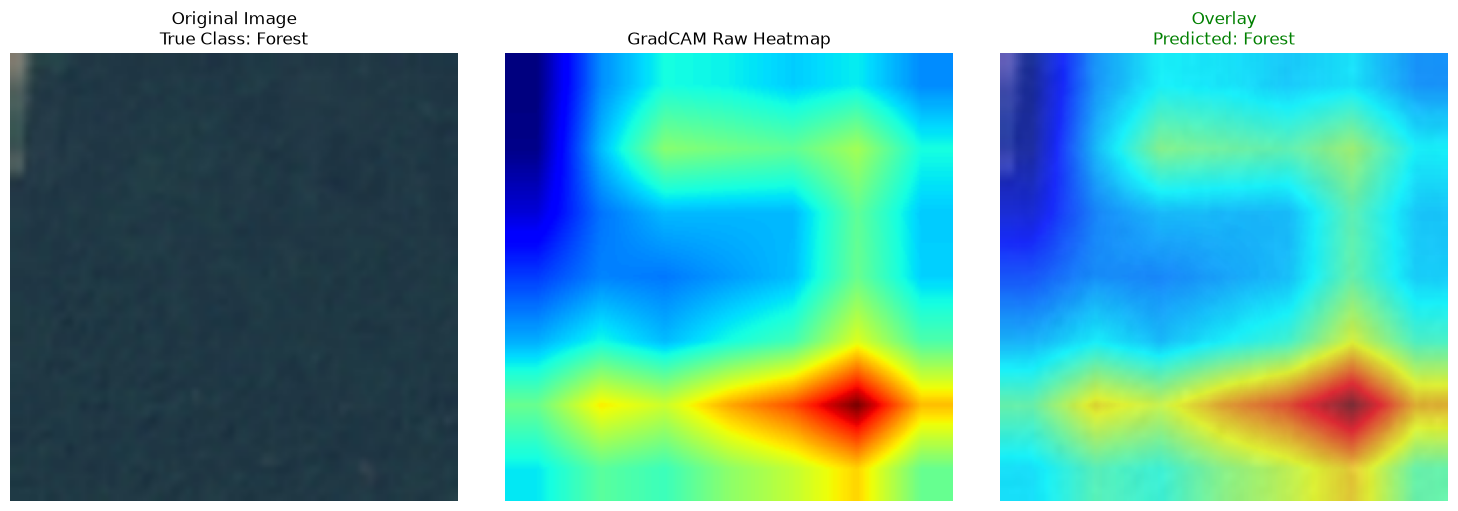

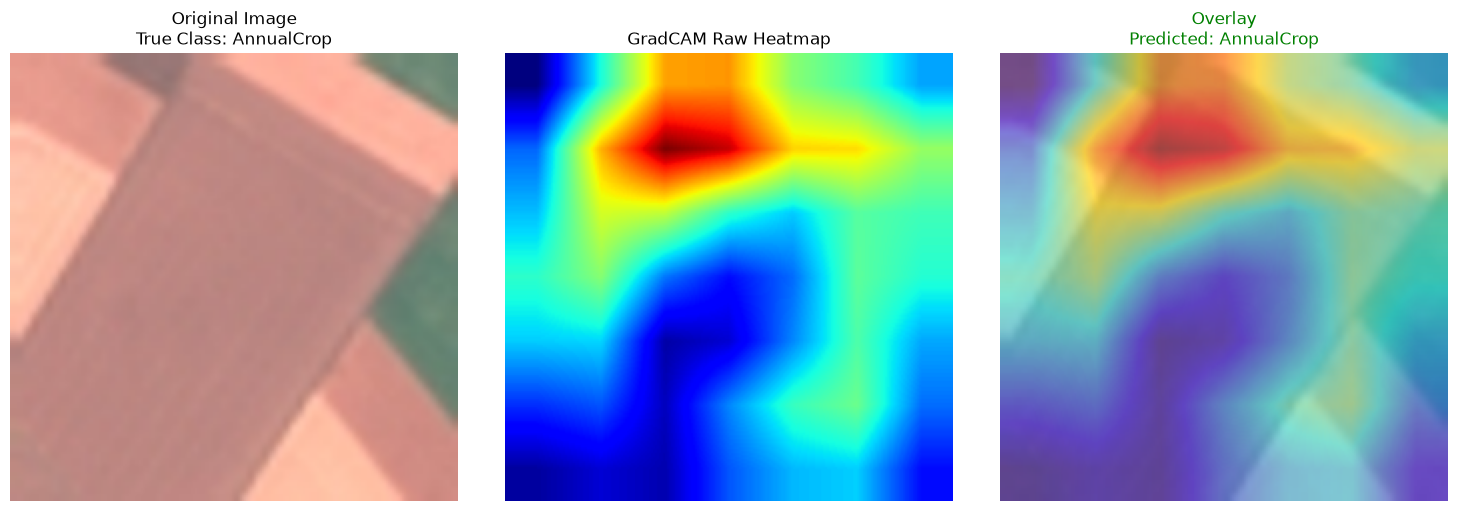

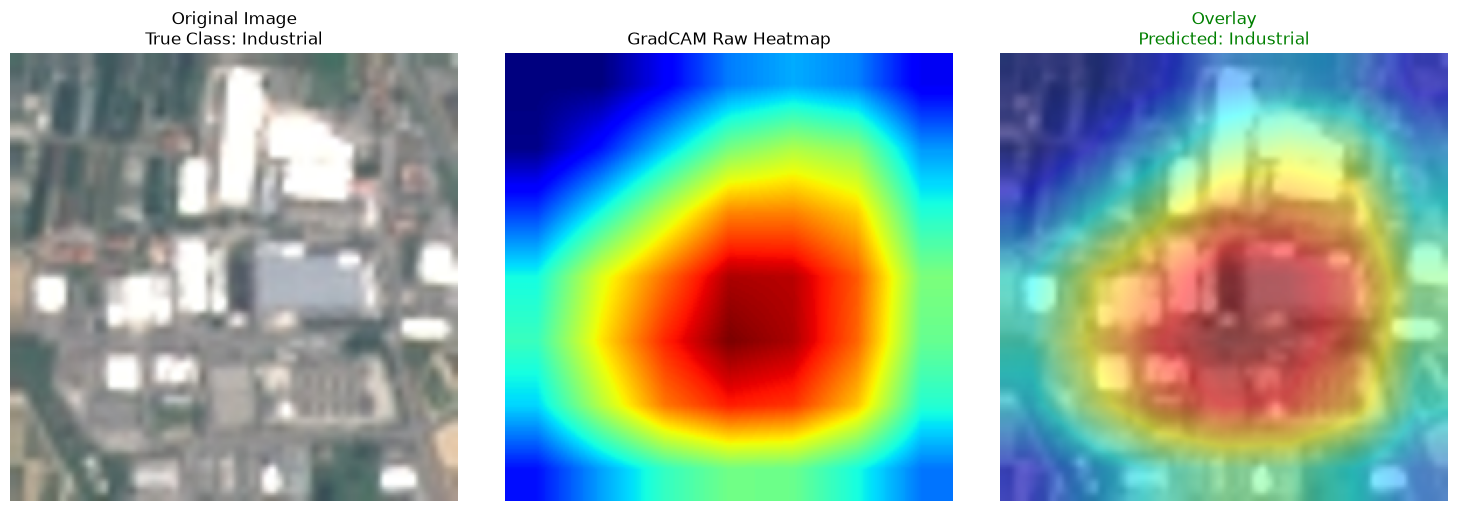

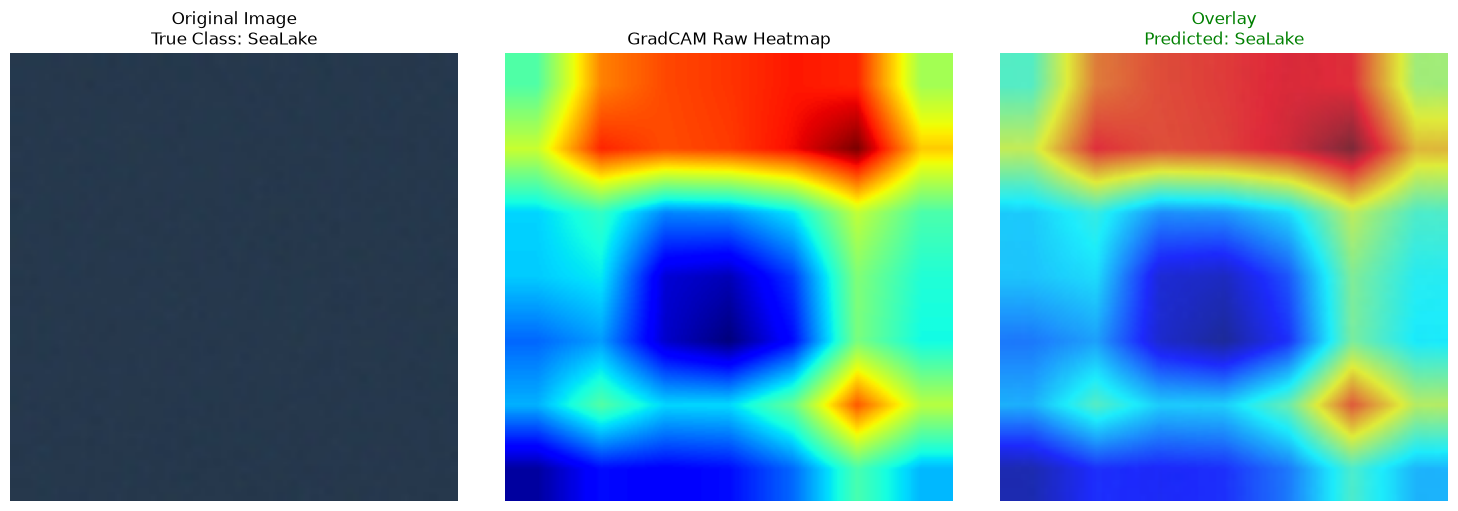

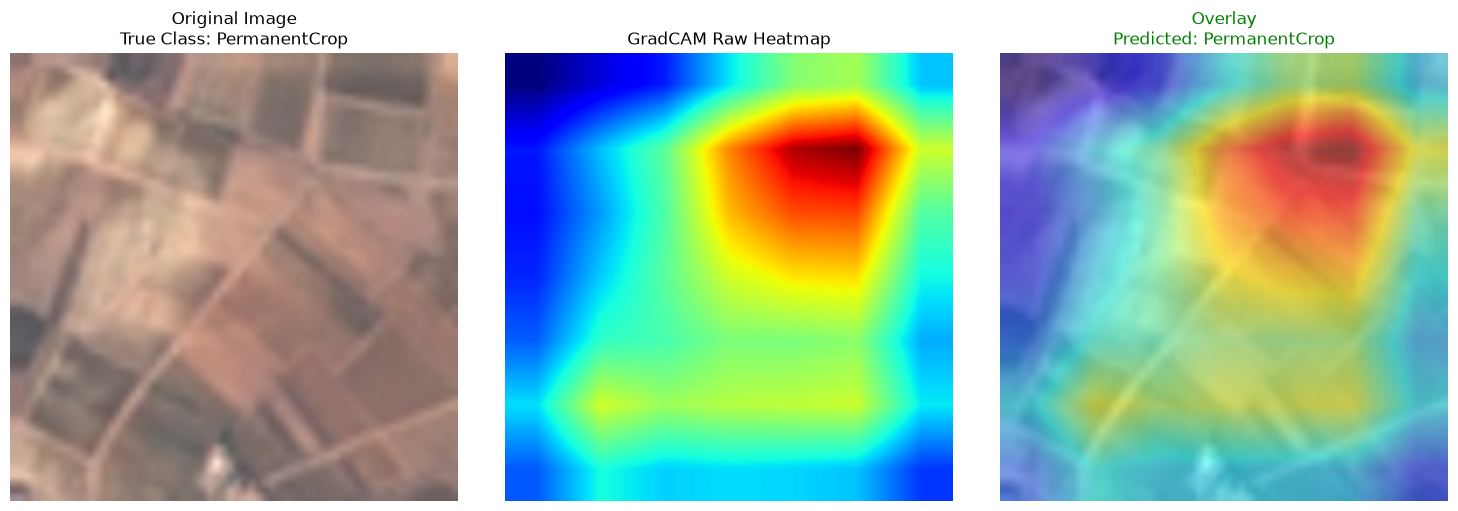

In [4]:
import random
import os

print("Generating GradCAM interpretations for 5 random samples across different classes...")
for cls_idx in random.sample(range(num_classes), 5):
    cls_name = classes[cls_idx]
    cls_dir = os.path.join(EUROSAT_DIR, cls_name)
    if os.path.isdir(cls_dir):
        img_name = random.choice(os.listdir(cls_dir))
        img_path = os.path.join(cls_dir, img_name)
        
        visualize_gradcam(img_path, cls_idx)